In [1]:
import numpy as np 
import scipy as sp 
import matplotlib.pyplot as plt

In [58]:
def gaussian_kernel(u):
    return np.exp(-0.5 * u**2) / np.sqrt(2 * np.pi)

In [ ]:
def gaussianKDE(x, observations, h=0.3):
    observations = np.asarray(observations, dtype=float)
    x = np.asarray(x, dtype=float)

    u = (x[..., np.newaxis] - observations) / h
    kernels = gaussian_kernel(u)
    return np.mean(kernels, axis=-1) / h

In [60]:
def optimal_h(observations):
    n = len(observations)
    s = observations.std() 
    iqr = sp.stats.iqr(observations)

    return min(0.9 * s, (2/3) * iqr) / np.pow(n, (1/5))

#### True Distribution

A kernel-density estimation should replicate the simulated log-normal distribution by averaging a gaussian-kernel at each point. Suppose we are estimating density at  point $x^*$. We will evaluate the probability density of observing this value, with respect to the gaussian-distributions centered at each observation point with a standard-deviation $h$, and we will average all of these individual densities to form our estimate $\hat f(x^*)$. 

In [81]:
observations = np.random.lognormal(0, 1, 100)
observations.sort()

In [82]:
h_opt = optimal_h(observations)

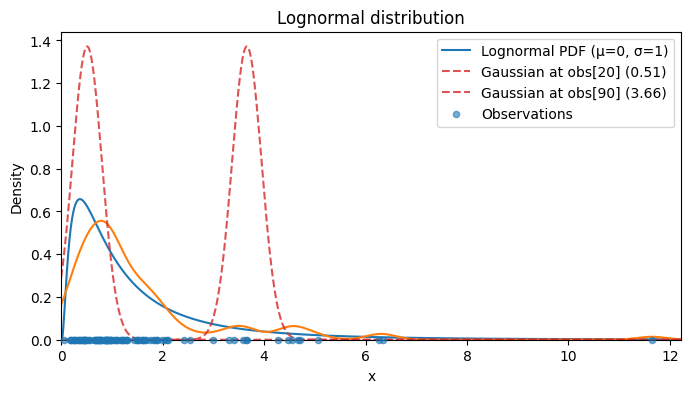

In [84]:
x = np.linspace(0, observations.max() * 1.05, 1000)
density = sp.stats.lognorm.pdf(x, s=1, scale=np.exp(0))


fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(x, density, label="Lognormal PDF (μ=0, σ=1)")
ax.plot(x, gaussianKDE(x, observations, h=h_opt))

obs_idx_1 = 20
obs_val_1 = observations[obs_idx_1]
gaussian_1 = sp.stats.norm.pdf(x, loc=obs_val_1, scale=h_opt)

obs_idx_2 = 90
obs_val_2 = observations[obs_idx_2]
gaussian_2 = sp.stats.norm.pdf(x, loc=obs_val_2, scale=h_opt)

ax.plot(
    x, 
    gaussian_1, 
    linestyle="--", 
    color="tab:red", 
    alpha=0.8,
    label=f"Gaussian at obs[{obs_idx_1}] ({obs_val_1:.2f})"
)

ax.plot(
    x, 
    gaussian_2, 
    linestyle="--", 
    color="tab:red", 
    alpha=0.8,
    label=f"Gaussian at obs[{obs_idx_2}] ({obs_val_2:.2f})"
)

ax.scatter(
    observations, 
    np.zeros_like(observations), 
    s=20, 
    alpha=0.6,
    zorder=3, 
    clip_on=False, 
    label="Observations"
)

ax.set(xlabel="x", ylabel="Density", title="Lognormal distribution", xlim=(0, x[-1]), ylim=(0, None))
ax.legend()
plt.show()

#### Multivariate Implementation

#### Cleaner Class Implementation

In [85]:
class KDE_Estimator:
    pass